In [90]:
#Librerias
import pandas as pd
import numpy as np
from scipy import stats

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

In [91]:
# Identificación del grupo
C1 = 2028596201
C2 = 2035384971
S = C1 + C2                      # 4063981172

#Parámetros derivados de S
SEMILLA = S
TAU     = 180 + 10 * (S % 9)                         # 230 ms
EPS     = 0.01 * (1 + S % 3)                         # 0.03
CONF    = {0: 0.90, 1: 0.95, 2: 0.99}[S % 3]         # 0.99
ALPHA   = 1 - CONF
G_CREC  = 1.4 + 0.1 * (S % 7)                        # 2.0
T1      = 80 + 10 * (S % 5)                          # 100 KB
T2      = 400 + 25 * (S % 5)                         # 450 KB
PI      = (4 + S % 6) / 1000                         # 0.006
K_MAX   = 4 + (S % 5)                                # 6
R_DESP  = S % 6                                      # 2
N_CONS  = 10 + (S % 11)                              # 19
C0      = 2                                          # GPUs del pool real (enunciado)

#Única fuente de aleatoriedad del notebook
rng = np.random.default_rng(SEMILLA)

#Estilo de figuras
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

print(f"C1={C1}  C2={C2}  S={S}")
print(f"tau={TAU} ms | eps={EPS} | 1-alpha={CONF} | g={G_CREC:.1f}")
print(f"t1={T1} KB | t2={T2} KB | pi={PI} | k_max={K_MAX} | r={R_DESP} | N={N_CONS}")

C1=2028596201  C2=2035384971  S=4063981172
tau=230 ms | eps=0.03 | 1-alpha=0.99 | g=2.0
t1=100 KB | t2=450 KB | pi=0.006 | k_max=6 | r=2 | N=19


In [92]:
# Cargar el dataset principal de solicitudes
df = pd.read_csv('/content/solicitudes.csv')

# Definir variables clave
gpu = df['gpu_ms']
cache = df['cache_hit'].astype(bool)
x = gpu[~cache]

n = len(gpu)
n_x = len(x)
Z = stats.norm.ppf(1 - ALPHA / 2)

# También extraemos tam_nc para la discusión crítica (no cachés)
tam_nc = df.loc[~cache, 'tam_kb']

# Definir las funciones de estimación de la distribución Gamma
def gamma_momentos(data):
    m = data.mean()
    v = data.var(ddof=1)
    th = v / m
    k = m / th
    return k, th

def gamma_sesgo(data):
    m = data.mean()
    g1 = stats.skew(data)
    k = (2 / g1) ** 2 if g1 > 0 else 1.0
    th = m / k
    return k, th

print(f"Datos cargados correctamente. n = {n}, n_x = {n_x}, Z = {Z:.4f}")

Datos cargados correctamente. n = 32472, n_x = 21106, Z = 2.5758


**C1.**

G = 0 con probabilidad p (caché)  |  G = X ~ Gamma(k, theta) con probabilidad 1-p

F_G(g) = 0 si g<0 ;  F_G(g) = p + (1-p) F_X(g) si g>=0

E[G] = (1-p) k theta                              (ley de la esperanza total)

Var(G) = (1-p) k theta^2 + p(1-p) (k theta)^2     (ley de la varianza total)

M_G(t) = p + (1-p) (1 - theta t)^(-k),  t < 1/theta   (función generadora de momentos)

In [93]:
# C1. Distribución completa de G (variable aleatoria MIXTA, semana 5)
print("\n C1 ")
p_hat = cache.mean()                                    # estimador de Bernoulli
ep_p = Z * np.sqrt(p_hat * (1 - p_hat) / n)             # IC por TLC (distribución muestral)
print(f"p_hat = {p_hat:.4f}  IC {CONF:.0%} = [{p_hat - ep_p:.4f}, {p_hat + ep_p:.4f}]")

k_hat, th_hat = gamma_momentos(x)   # modelo principal: método de momentos (media y varianza)
EG = (1 - p_hat) * k_hat * th_hat
VarG = (1 - p_hat) * k_hat * th_hat**2 + p_hat * (1 - p_hat) * (k_hat * th_hat) ** 2


 C1 
p_hat = 0.3500  IC 99% = [0.3432, 0.3568]


In [94]:
# Verificación 1: derivadas numéricas de la FGM en t = 0 (momentos de G)
def fgm_G(t):
    return p_hat + (1 - p_hat) * (1 - th_hat * t) ** (-k_hat)
h = 1e-3 / th_hat
m1 = (fgm_G(h) - fgm_G(-h)) / (2 * h)                   # M'(0)  = E[G]
m2 = (fgm_G(h) - 2 * fgm_G(0) + fgm_G(-h)) / h**2       # M''(0) = E[G^2]

In [95]:
# Verificación 2: simulación de Montecarlo de la mezcla
M_mc = 1_000_000
G_mc = np.where(rng.random(M_mc) < p_hat, 0.0, rng.gamma(k_hat, th_hat, M_mc))

media_G, var_G = gpu.mean(), gpu.var(ddof=1)
ep_mean = Z * np.sqrt(var_G / n)                        # IC de la media por TLC
print(f"E[G]   modelo = {EG:.3f} | FGM = {m1:.3f} | Montecarlo = {G_mc.mean():.3f} | "
      f"muestral = {media_G:.3f}  IC {CONF:.0%} = [{media_G - ep_mean:.3f}, {media_G + ep_mean:.3f}]")
print(f"Var(G) modelo = {VarG:.3f} | FGM = {m2 - m1**2:.3f} | Montecarlo = {G_mc.var():.3f} | "
      f"muestral = {var_G:.3f}")

E[G]   modelo = 32.495 | FGM = 32.495 | Montecarlo = 32.421 | muestral = 32.499  IC 99% = [31.913, 33.085]
Var(G) modelo = 1679.602 | FGM = 1679.602 | Montecarlo = 1671.040 | muestral = 1679.683


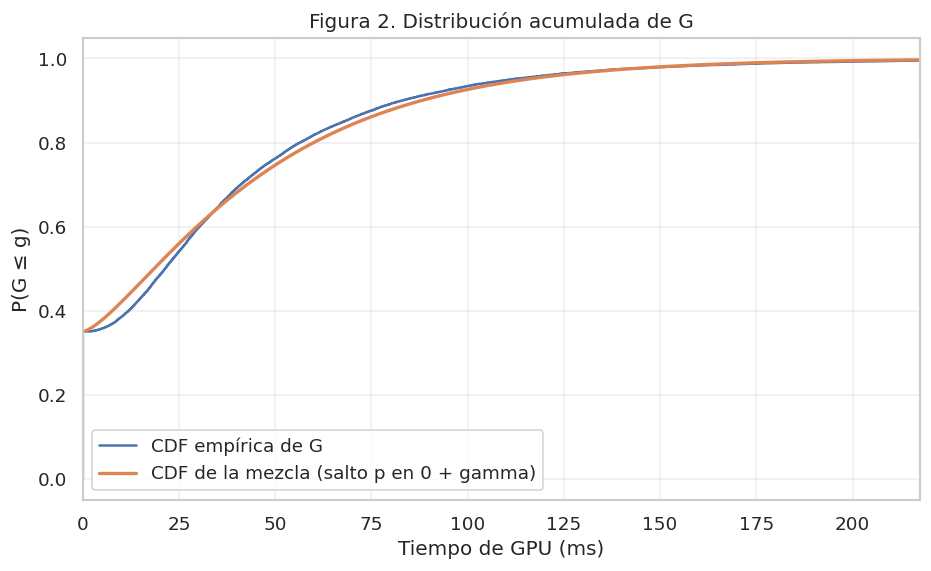

In [96]:
# Figura 2: CDF empírica vs CDF de la mezcla
gpu_clean = gpu.dropna()
n_clean = len(gpu_clean)
g_ord = np.sort(gpu_clean)
grid_G = np.linspace(0, np.quantile(gpu_clean, 0.995), 500)
cdf_G = p_hat + (1 - p_hat) * stats.gamma.cdf(grid_G, k_hat, scale=th_hat)
plt.figure(figsize=(9, 5))
plt.step(g_ord, np.arange(1, n_clean + 1) / n_clean, where="post", label="CDF empírica de G")
plt.plot(grid_G, cdf_G, linewidth=2, label="CDF de la mezcla (salto p en 0 + gamma)")
plt.xlim(0, grid_G[-1])
plt.title("Figura 2. Distribución acumulada de G")
plt.xlabel("Tiempo de GPU (ms)")
plt.ylabel("P(G ≤ g)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("figura2_CDF_G.png", dpi=200, bbox_inches="tight")
plt.show()

**C2.**

Modelo: X ~ Gamma(k, theta). Dos métodos de estimación, ambos basados en momentos:

Método 1 (media y varianza): k theta = m ,  k theta^2 = s^2

Método 2 (media y sesgo)   : k theta = m ,  sesgo = 2 / √(k)

In [97]:
# C2. Ajuste de la parte continua de G
print("\n C2 ")
m_x, s2_x = x.mean(), x.var(ddof=1)
k_ses, th_ses = gamma_sesgo(x)
print(f"Método 1 (media, varianza): k = {k_hat:.4f}, theta = {th_hat:.4f}")
print(f"Método 2 (media, sesgo)   : k = {k_ses:.4f}, theta = {th_ses:.4f}")


 C2 
Método 1 (media, varianza): k = 1.4623, theta = 34.1889
Método 2 (media, sesgo)   : k = 1.0000, theta = 49.9941


In [98]:
# Bondad de ajuste numérica: modelos candidatos del syllabus (gamma, exponencial, normal)
x_ord = np.sort(x)
F_emp = np.arange(1, n_x + 1) / n_x
modelos = {
    "gamma (media, var.)": stats.gamma(k_hat, scale=th_hat),
    "gamma (media, sesgo)": stats.gamma(k_ses, scale=th_ses),
    "exponencial": stats.expon(scale=m_x),
    "normal": stats.norm(m_x, x.std(ddof=1)),
}
filas = {"muestra": [stats.skew(x), stats.kurtosis(x)] +
         [np.quantile(x, q) for q in (0.50, 0.90, 0.99)] + [0.0]}
for nombre, d in modelos.items():
    filas[nombre] = [d.stats(moments="s"), d.stats(moments="k")] + \
                    [d.ppf(q) for q in (0.50, 0.90, 0.99)] + \
                    [np.max(np.abs(F_emp - d.cdf(x_ord)))]
tabla_gof = pd.DataFrame(filas, index=["sesgo", "curtosis*", "cuantil 0,50", "cuantil 0,90",
                                       "cuantil 0,99", "máx |F_emp - F|"]).astype(float)
print("\nMuestra vs modelos candidatos (*curtosis en exceso):\n", tabla_gof.round(3))


Muestra vs modelos candidatos (*curtosis en exceso):
                  muestra  gamma (media, var.)  gamma (media, sesgo)  exponencial   normal
sesgo                NaN                1.654                 2.000        2.000    0.000
curtosis*            NaN                4.103                 6.000        6.000    0.000
cuantil 0,50         NaN               39.173                34.653       34.653   49.994
cuantil 0,90         NaN              104.827               115.116      115.116  102.977
cuantil 0,99         NaN              191.329               230.231      230.231  146.172
máx |F_emp - F|      0.0                  NaN                   NaN          NaN      NaN


In [99]:
# Intervalos de confianza por simulación de Montecarlo (distribución muestral del estimador)
B = 1000
sim_k, sim_th = np.empty(B), np.empty(B)
for b in range(B):
    sim_k[b], sim_th[b] = gamma_momentos(rng.gamma(k_hat, th_hat, n_x))
lo, hi = 100 * ALPHA / 2, 100 * (1 - ALPHA / 2)
print(f"IC {CONF:.0%} (Montecarlo) k     = [{np.percentile(sim_k, lo):.4f}, {np.percentile(sim_k, hi):.4f}]")
print(f"IC {CONF:.0%} (Montecarlo) theta = [{np.percentile(sim_th, lo):.4f}, {np.percentile(sim_th, hi):.4f}]")

IC 99% (Montecarlo) k     = [1.4143, 1.5135]
IC 99% (Montecarlo) theta = [32.9321, 35.4165]


In [100]:
# Discusión crítica: ¿es adecuado el modelo marginal? Esperanza condicional E[G | clase] (semana 14)
clase = pd.cut(tam_nc, [0, T1, T2, np.inf], right=False,
               labels=[f"pequeña (<{T1})", f"mediana ({T1}-{T2})", f"grande (≥{T2})"])
tabla = pd.DataFrame({"clase": clase, "gpu_ms": x}).groupby("clase", observed=True)["gpu_ms"].agg(
    ["count", "mean", "std"])
print("\nE[G | clase de tamaño, no caché]:\n", tabla.round(3))
if "version" in df.columns:
    print("\nE[G | versión, no caché]:\n",
          df.loc[~cache].groupby("version")["gpu_ms"].agg(["count", "mean", "std"]).round(3))
# Ley de la varianza total: fracción de Var(X) explicada por la clase
medias_cl = tabla["mean"].to_numpy()
pesos = tabla["count"].to_numpy() / n_x
var_entre = np.sum(pesos * (medias_cl - m_x) ** 2)
print(f"Fracción de Var(X) explicada por la clase = {var_entre / x.var(ddof=0):.3f}")


E[G | clase de tamaño, no caché]:
                    count    mean     std
clase                                   
pequeña (<100)      3043  22.102  13.418
mediana (100-450)  15074  46.034  30.726
grande (≥450)       2971  98.653  62.568

E[G | versión, no caché]:
          count    mean     std
version                       
A        10474  54.179  44.428
B        10614  45.865  37.603
Fracción de Var(X) explicada por la clase = 0.267


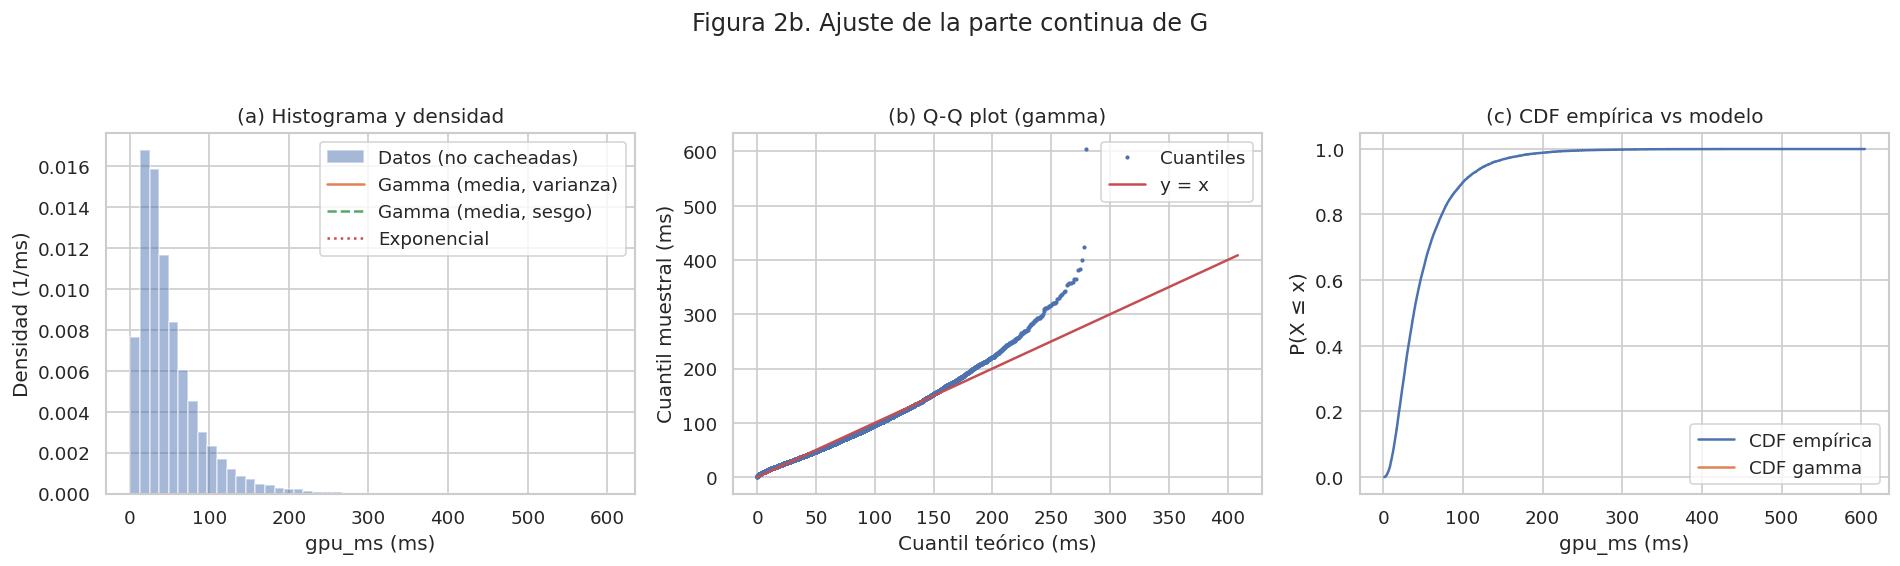

In [101]:
# Figura 2b: histograma + densidades, Q-Q y CDF
probs = (np.arange(1, n_x + 1) - 0.5) / n_x
grid = np.linspace(x.min(), np.quantile(x, 0.995), 400)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].hist(x, bins=50, density=True, alpha=0.5, label="Datos (no cacheadas)")
ax[0].plot(grid, stats.gamma.pdf(grid, k_hat, scale=th_hat), label="Gamma (media, varianza)")
ax[0].plot(grid, stats.gamma.pdf(grid, k_ses, scale=th_ses), "--", label="Gamma (media, sesgo)")
ax[0].plot(grid, stats.expon.pdf(grid, scale=m_x), ":", label="Exponencial")
ax[0].set(title="(a) Histograma y densidad", xlabel="gpu_ms (ms)", ylabel="Densidad (1/ms)")
ax[0].legend()
q_teo = stats.gamma.ppf(probs, k_hat, scale=th_hat)
ax[1].plot(q_teo, x_ord, ".", markersize=3, label="Cuantiles")
lim = [min(q_teo.min(), x_ord.min()), max(q_teo.max(), x_ord.max())]
ax[1].plot(lim, lim, "r-", label="y = x")
ax[1].set(title="(b) Q-Q plot (gamma)", xlabel="Cuantil teórico (ms)", ylabel="Cuantil muestral (ms)")
ax[1].legend()
ax[2].step(x_ord, F_emp, where="post", label="CDF empírica")
ax[2].plot(grid, stats.gamma.cdf(grid, k_hat, scale=th_hat), label="CDF gamma")
ax[2].set(title="(c) CDF empírica vs modelo", xlabel="gpu_ms (ms)", ylabel="P(X ≤ x)")
ax[2].legend()
fig.suptitle("Figura 2b. Ajuste de la parte continua de G")
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig("figura2b_ajuste_G.png", dpi=200, bbox_inches="tight")
plt.show()

**C3.**

In [102]:
# C3. ¿Admite red_ms un modelo normal? (semana 12)
print("\n C3 ")
red = df['red_ms'].dropna()
n_r = len(red)
mu_r, sd_r = red.mean(), red.std(ddof=1)
print(f"media = {mu_r:.3f} ms, desviación estándar = {sd_r:.3f} ms (limpiados {len(df) - n_r} nulos)")


 C3 
media = 26.418 ms, desviación estándar = 3.903 ms (limpiados 32 nulos)


In [103]:
# Criterio 1: sesgo y curtosis. Bajo normalidad ambos (en exceso) valen 0, con errores
# estándar aproximados sqrt(6/n) y sqrt(24/n).
sesgo, curt = stats.skew(red), stats.kurtosis(red)
print(f"Criterio 1 | sesgo = {sesgo:.3f} (z = {sesgo / np.sqrt(6 / n_r):.1f}), "
      f"curtosis en exceso = {curt:.3f} (z = {curt / np.sqrt(24 / n_r):.1f})")

Criterio 1 | sesgo = 0.010 (z = 0.7), curtosis en exceso = 0.022 (z = 0.8)


In [104]:
# Criterio 2: regla empírica 68-95-99,7 de la normal
print("Criterio 2 | proporción dentro de ±k·sigma (empírica vs normal):")
for kk in (1, 2, 3):
    emp = np.mean(np.abs(red - mu_r) <= kk * sd_r)
    teo = stats.norm.cdf(kk) - stats.norm.cdf(-kk)
    print(f"  ±{kk}σ: {emp:.4f} vs {teo:.4f}")

Criterio 2 | proporción dentro de ±k·sigma (empírica vs normal):
  ±1σ: 0.6855 vs 0.6827
  ±2σ: 0.9537 vs 0.9545
  ±3σ: 0.9973 vs 0.9973


In [105]:
# Criterio 3 (gráfico): Q-Q plot y cola en la Figura 3

# P(red > x) para tres valores de x (elección propia: media + 1, 2 y 3 desviaciones)
print(f"\nP(red > x) con IC {CONF:.0%} (TLC sobre la proporción) vs modelo normal:")
for kk in (1, 2, 3):
    xv = round(mu_r + kk * sd_r, 1)
    pe = np.mean(red > xv)
    ep = Z * np.sqrt(pe * (1 - pe) / n_r)
    pn = 1 - stats.norm.cdf(xv, mu_r, sd_r)
    print(f"  x = {xv:7.1f} ms | empírica = {pe:.5f} [{max(pe - ep, 0):.5f}, {min(pe + ep, 1):.5f}]"
          f" | normal = {pn:.5f}")

# Percentil 99,9 %: el número de observaciones <= percentil verdadero es Binomial(n, q),
# lo que da un IC para el percentil usando estadísticos de orden (sin suponer ninguna forma).
q = 0.999
xs = np.sort(red)
def ic_percentil(ordenados, q):
    m = len(ordenados)
    lo_r = max(int(stats.binom.ppf(ALPHA / 2, m, q)), 1)
    hi_r = min(int(stats.binom.ppf(1 - ALPHA / 2, m, q)) + 1, m)
    return ordenados[lo_r - 1], ordenados[hi_r - 1]
q_emp = np.quantile(red, q)
q_lo, q_hi = ic_percentil(xs, q)
q_norm = mu_r + stats.norm.ppf(q) * sd_r
print(f"\nPercentil 99,9 %: empírico = {q_emp:.2f} ms, IC {CONF:.0%} (binomial) = "
      f"[{q_lo:.2f}, {q_hi:.2f}] | modelo normal = {q_norm:.2f} ms")

# Verificación por Montecarlo de la cobertura del IC (muestras normales, percentil conocido)
cubre, R = 0, 1000
q_verd = stats.norm.ppf(q)
for _ in range(R):
    zs = np.sort(rng.standard_normal(n_r))
    a, b = ic_percentil(zs, q)
    cubre += (a <= q_verd <= b)
print(f"Cobertura simulada del IC binomial: {cubre / R:.3f} (nominal {CONF})")


P(red > x) con IC 99% (TLC sobre la proporción) vs modelo normal:
  x =    30.3 ms | empírica = 0.15746 [0.15225, 0.16267] | normal = 0.15999
  x =    34.2 ms | empírica = 0.02411 [0.02191, 0.02630] | normal = 0.02309
  x =    38.1 ms | empírica = 0.00139 [0.00085, 0.00192] | normal = 0.00138

Percentil 99,9 %: empírico = 38.55 ms, IC 99% (binomial) = [38.01, 39.26] | modelo normal = 38.48 ms
Cobertura simulada del IC binomial: 0.991 (nominal 0.99)


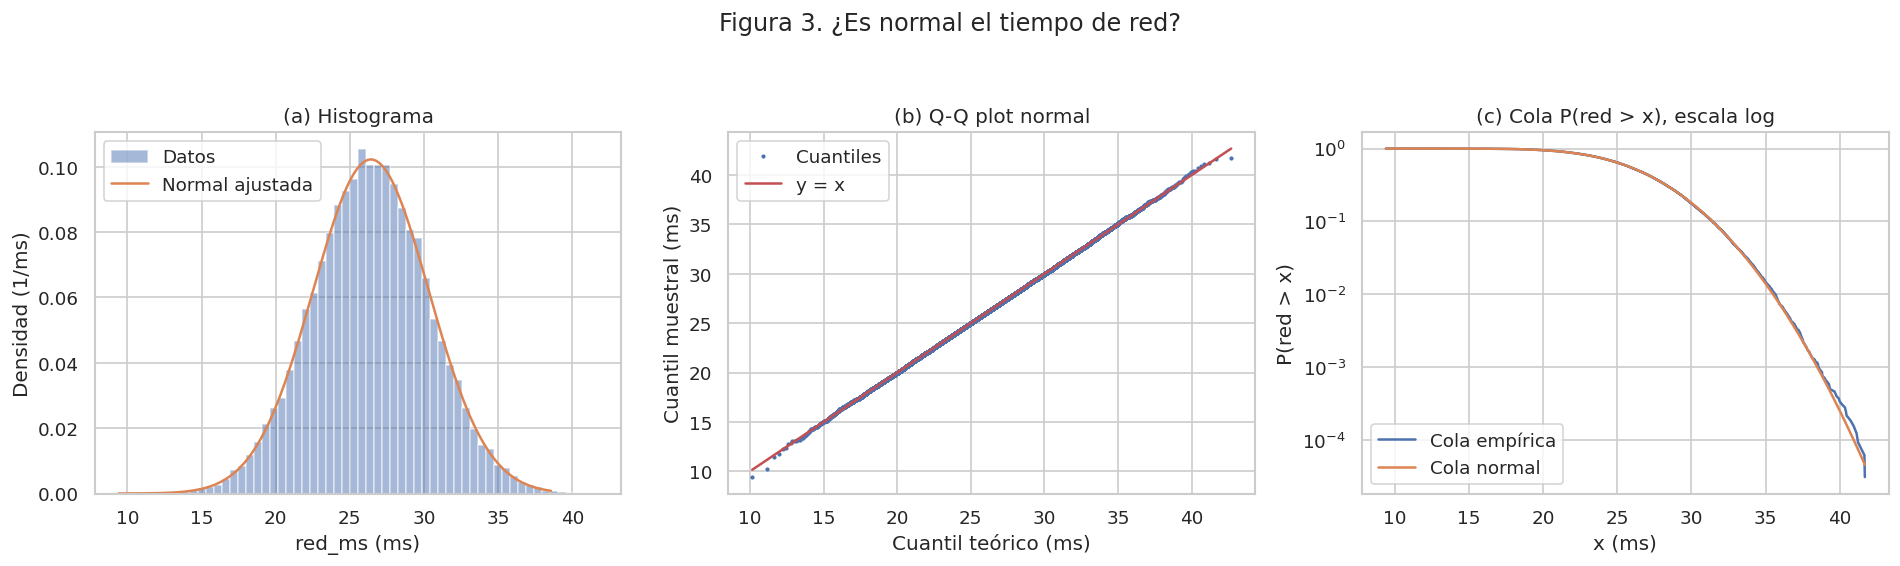

In [106]:
# Figura 3
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
gr = np.linspace(red.min(), np.quantile(red, 0.999), 400)
ax[0].hist(red, bins=60, density=True, alpha=0.5, label="Datos")
ax[0].plot(gr, stats.norm.pdf(gr, mu_r, sd_r), label="Normal ajustada")
ax[0].set(title="(a) Histograma", xlabel="red_ms (ms)", ylabel="Densidad (1/ms)")
ax[0].legend()
pr = (np.arange(1, n_r + 1) - 0.5) / n_r
qt = stats.norm.ppf(pr, mu_r, sd_r)
ax[1].plot(qt, xs, ".", markersize=3, label="Cuantiles")
ax[1].plot([qt.min(), qt.max()], [qt.min(), qt.max()], "r-", label="y = x")
ax[1].set(title="(b) Q-Q plot normal", xlabel="Cuantil teórico (ms)", ylabel="Cuantil muestral (ms)")
ax[1].legend()
ax[2].semilogy(xs, 1 - np.arange(1, n_r + 1) / n_r + 1 / n_r, label="Cola empírica")
ax[2].semilogy(xs, 1 - stats.norm.cdf(xs, mu_r, sd_r), label="Cola normal")
ax[2].set(title="(c) Cola P(red > x), escala log", xlabel="x (ms)", ylabel="P(red > x)")
ax[2].legend()
fig.suptitle("Figura 3. ¿Es normal el tiempo de red?")
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig("figura3_red.png", dpi=200, bbox_inches="tight")
plt.show()

**C4.**

C4. P(T_N > N (m_hat + 15)), con T_N = suma de N tiempos de GPU no cacheados

Aproximación 1: TLC (semana 16): T_N ~ Normal(N m, N s^2), con m y s muestrales.

Aproximación 2: bajo el modelo gamma, la FGM de la suma es el producto de las FGM:

(1 - theta t)^(-N k)  =>  T_N ~ Gamma(N k, theta)  (resultado exacto del modelo)

Referencia: simulación de Montecarlo (semana 2).

In [107]:

print("\n C4 ")
N = N_CONS
m_hat, s_hat = x.mean(), x.std(ddof=1)
umbral = N * (m_hat + 15)
print(f"N = {N}, m_hat = {m_hat:.3f} ms, s_hat = {s_hat:.3f} ms, umbral = {umbral:.2f} ms")

p_tlc = 1 - stats.norm.cdf(umbral, N * m_hat, np.sqrt(N) * s_hat)
p_gamma = stats.gamma.sf(umbral, a=N * k_hat, scale=th_hat)

M_sim = 200_000
T_emp = rng.choice(x, size=(M_sim, N), replace=True).sum(axis=1)    # desde los datos
T_mod = rng.gamma(k_hat, th_hat, size=(M_sim, N)).sum(axis=1)       # desde el modelo gamma
resultados = {}
for nombre, T in (("Montecarlo (datos)", T_emp), ("Montecarlo (modelo gamma)", T_mod)):
    pe = np.mean(T > umbral)
    ep = Z * np.sqrt(pe * (1 - pe) / M_sim)
    resultados[nombre] = pe
    print(f"{nombre:27s}: {pe:.5f}  IC {CONF:.0%} = [{pe - ep:.5f}, {pe + ep:.5f}]")
print(f"{'TLC (normal)':27s}: {p_tlc:.5f}")
print(f"{'Gamma exacta (vía FGM)':27s}: {p_gamma:.5f}")
ref = resultados["Montecarlo (datos)"]
print(f"Error relativo vs Montecarlo (datos): TLC = {100 * (p_tlc - ref) / ref:+.1f} %, "
      f"gamma = {100 * (p_gamma - ref) / ref:+.1f} %")


 C4 
N = 19, m_hat = 49.994 ms, s_hat = 41.343 ms, umbral = 1234.89 ms
Montecarlo (datos)         : 0.06821  IC 99% = [0.06676, 0.06966]
Montecarlo (modelo gamma)  : 0.06563  IC 99% = [0.06421, 0.06706]
TLC (normal)               : 0.05688
Gamma exacta (vía FGM)     : 0.06576
Error relativo vs Montecarlo (datos): TLC = -16.6 %, gamma = -3.6 %


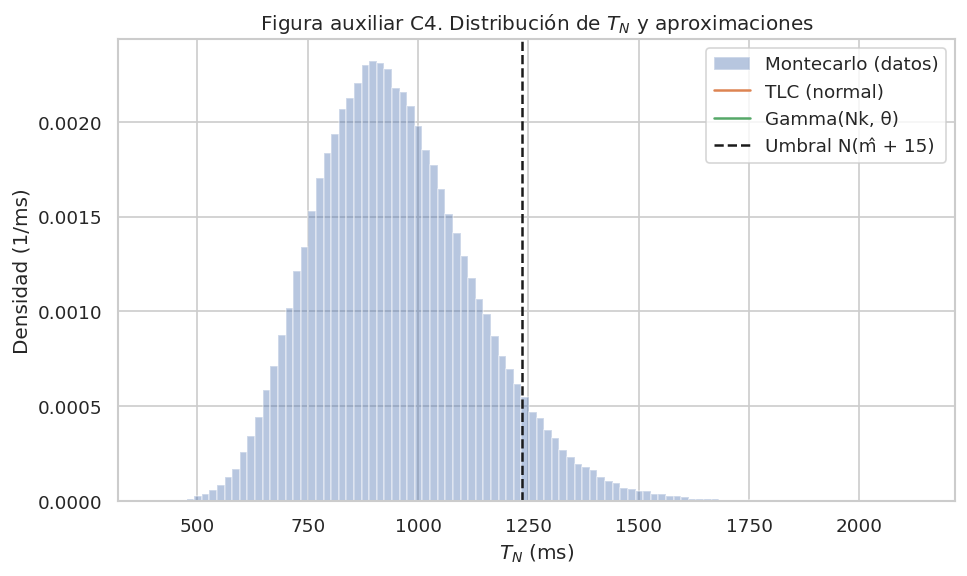

In [108]:
# Figura auxiliar C4
plt.figure(figsize=(9, 5))
gT = np.linspace(np.quantile(T_emp, 0.001), np.quantile(T_emp, 0.999), 400)
plt.hist(T_emp, bins=100, density=True, alpha=0.4, label="Montecarlo (datos)")
plt.plot(gT, stats.norm.pdf(gT, N * m_hat, np.sqrt(N) * s_hat), label="TLC (normal)")
plt.plot(gT, stats.gamma.pdf(gT, a=N * k_hat, scale=th_hat), label="Gamma(Nk, θ)")
plt.axvline(umbral, color="k", linestyle="--", label="Umbral N(m̂ + 15)")
plt.title("Figura auxiliar C4. Distribución de $T_N$ y aproximaciones")
plt.xlabel("$T_N$ (ms)")
plt.ylabel("Densidad (1/ms)")
plt.legend()
plt.savefig("figura_aux_C4.png", dpi=200, bbox_inches="tight")
plt.show()